# willmarley: choosing a motor, propeller, and battery

Tracks [issue #85](https://github.com/MarMar888/hav/issues/85).

We have three things to buy. Each gets its own section — the raw equations, the inputs
it brings, and a low/high range for every input (nothing is picked). Where a number is really a
*consequence* — pack size, pack rating, prop pitch — the model prints it as a shopping
note instead of pretending it's a choice. The loop is closed:
the battery's weight counts against the boat, the water's push-back is in the solve, and
the speed that comes out is a power-balanced speed, not a gear-ratio fantasy.

The chain, in words:

> **battery** gives volts and amps (and adds its own weight) → **motor(s)** turn them
> into torque and rpm → **propeller** turns shaft power into pull — never more than its
> disk can grip → the **water pushes back**, harder with weight and harder with speed →
> speed is where pull and push-back balance.

Section 5 draws this as a map. Every number below is computed from the ranges — edit any
bound and re-run.

## 1. The motor

A DC motor is two numbers deep down — `Kv` and `R` — plus two guardrails (`I0`, `I_max`).

```text
Kt  = 60 / (2π · Kv)        torque constant: N·m you get per amp
Q   = Kt · (I − I0)         torque out, for current in (I0 is lost to friction)
rpm = Kv · (V − I · R)      spin rate, for volts in (I·R is lost to the winding)
I  ≤ I_max                  the current guardrail — more amps than this melts it
```

`Kv` is the trade: a high-Kv motor spins faster per volt but makes less torque per
amp. You can't have both — `Kt · Kv` is a constant of nature (60/2π).

A motor also weighs something (`W_motor`), and the boat carries it — that bill comes due
in section 4. And nothing says one: `n_motors` (1 or 2) — twins double the shaft power,
the motor weight, and the draw on the pack, and each motor swings its own prop.

### How many volts does a motor actually need?

Flip the speed equation around and it answers directly:

```text
rpm = Kv · (V − I·R)        ->        V_needed  =  rpm / Kv  +  I · R
                                                   push-back    winding loss
```

A spinning motor is also a generator: it **pushes back** against the pack with `rpm / Kv`
volts. The pack only has to beat that push-back and cover the small `I·R` loss — nothing
more. And the rpm is not the pack's choice: **the propeller load sets the rpm** (section 6
solves it). Volts above `V_needed` do not spin a loaded motor faster — they only shove
more current through it, and current past `I_max` is forbidden anyway. So:

- pack voltage is sized by the **operating point**, the rpm your prop load settles at;
- the winding's rated `v_max` is a **ceiling, not a requirement** — on the SSS sheet it is
  simply `max_rpm / Kv`, the no-load spin limit;
- a low-Kv motor held down by a big prop runs happily on a small pack.

The chart below draws `V_needed`; the shopping lists in section 10 print it next to the
pack each ideal design actually chose.

input         low     high  unit
Kv            300     1200  rpm/V
R           0.005     0.05  ohm
I0              1        6  A
I_max          50      320  A
W_motor       0.4        5  lb
n_motors        1        2  -


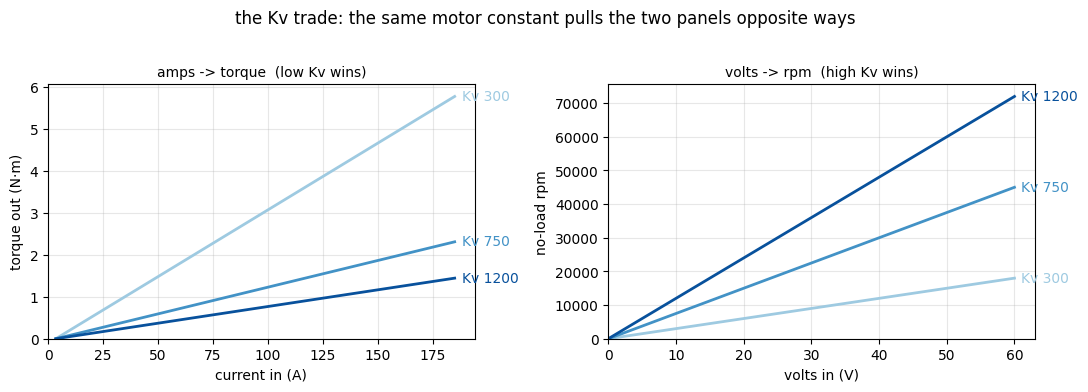

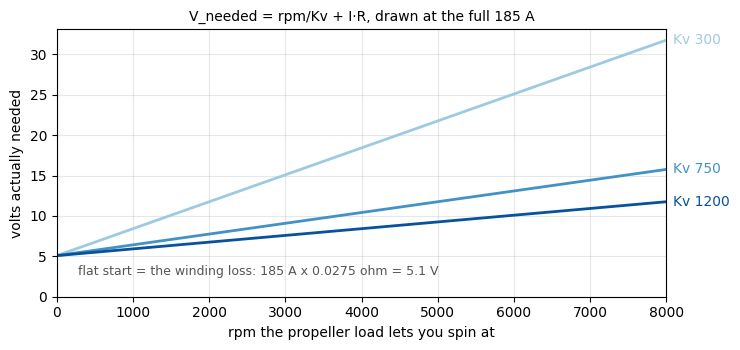

In [1]:
import math
import numpy as np
import matplotlib.pyplot as plt

RHO = 999.0  # water density, kg/m^3
SEQ = ["#9ecae1", "#4292c6", "#08519c"]  # low / mid / high of one knob, light -> dark

def lo_mid_hi(bounds, key):
    lo, hi = bounds[key]
    return [lo, (lo + hi) / 2, hi]

def show_bounds(bounds, units):
    w = max(len(k) for k in bounds)
    print(f"{'input':<{w}}  {'low':>7}  {'high':>7}  unit")
    for k, (lo, hi) in bounds.items():
        print(f"{k:<{w}}  {lo:>7g}  {hi:>7g}  {units[k]}")

MOTOR_BOUNDS = {
    "Kv":    (300.0, 1200.0),
    "R":     (0.005, 0.050),
    "I0":    (1.0, 6.0),
    "I_max": (50.0, 320.0),
    "W_motor": (0.4, 5.0),
    "n_motors": (1, 2),
}
MOTOR_UNITS = {"Kv": "rpm/V", "R": "ohm", "I0": "A", "I_max": "A", "W_motor": "lb", "n_motors": "-"}
show_bounds(MOTOR_BOUNDS, MOTOR_UNITS)

I0_mid = sum(MOTOR_BOUNDS["I0"]) / 2
Imax_mid = sum(MOTOR_BOUNDS["I_max"]) / 2

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.8))
for Kv, color in zip(lo_mid_hi(MOTOR_BOUNDS, "Kv"), SEQ):
    Kt = 60 / (2 * math.pi * Kv)
    I = np.linspace(I0_mid, Imax_mid, 50)
    ax1.plot(I, Kt * (I - I0_mid), color=color, lw=2)
    ax1.annotate(f"Kv {Kv:g}", (I[-1], Kt * (I[-1] - I0_mid)),
                 xytext=(5, 0), textcoords="offset points", color=color, va="center")
    V = np.linspace(0, 60, 2)
    ax2.plot(V, Kv * V, color=color, lw=2)
    ax2.annotate(f"Kv {Kv:g}", (V[-1], Kv * V[-1]),
                 xytext=(5, 0), textcoords="offset points", color=color, va="center")
ax1.set_xlabel("current in (A)"); ax1.set_ylabel("torque out (N·m)")
ax1.set_title("amps -> torque  (low Kv wins)", fontsize=10)
ax2.set_xlabel("volts in (V)"); ax2.set_ylabel("no-load rpm")
ax2.set_title("volts -> rpm  (high Kv wins)", fontsize=10)
for ax in (ax1, ax2):
    ax.grid(alpha=0.3); ax.set_xlim(left=0); ax.set_ylim(bottom=0)
    ax.margins(x=0.15)
fig.suptitle("the Kv trade: the same motor constant pulls the two panels opposite ways", y=1.02)
plt.tight_layout(); plt.show()

R_mid = sum(MOTOR_BOUNDS["R"]) / 2
rpm_ax = np.linspace(0, 8000, 100)
fig, ax = plt.subplots(figsize=(7.5, 3.6))
for Kv, color in zip(lo_mid_hi(MOTOR_BOUNDS, "Kv"), SEQ):
    V_need = rpm_ax / Kv + Imax_mid * R_mid
    ax.plot(rpm_ax, V_need, color=color, lw=2)
    ax.annotate(f"Kv {Kv:g}", (rpm_ax[-1], V_need[-1]), xytext=(5, 0),
                textcoords="offset points", color=color, va="center")
ax.annotate(f"flat start = the winding loss: {Imax_mid:g} A x {R_mid:g} ohm = {Imax_mid * R_mid:.1f} V",
            (rpm_ax[2], Imax_mid * R_mid), xytext=(6, -14), textcoords="offset points",
            fontsize=9, color="#555555")
ax.set_xlabel("rpm the propeller load lets you spin at")
ax.set_ylabel("volts actually needed")
ax.set_title(f"V_needed = rpm/Kv + I·R, drawn at the full {Imax_mid:g} A", fontsize=10)
ax.grid(alpha=0.3); ax.set_xlim(0, rpm_ax[-1]); ax.set_ylim(bottom=0)
ax.margins(x=0.15)
plt.tight_layout(); plt.show()

## 2. The propeller

Four raw equations — the load it puts on the motor, the most push its disk can give, how
well it converts power to pull, and the thread the finished design will tell you to buy:

```text
Q        = K_Q · ρ · n² · D⁵          torque the water demands to spin it
                                      (n in rev/s, D in meters, ρ = water density)
T        = K_T · ρ · n² · D⁴          the most push this disk can give at that rpm
P_pull   = η_p · P_shaft              pull-through-the-water power, from shaft power
pitch    = speed · 1056 / (rpm · 0.8) the thread to buy, sized so the prop runs at ~80%
                                      of its pitch speed (1056 converts in/min -> mph)
```

What each knob really is:

- **D (diameter)** — the load knob. It enters to the **5th power**, so small diameter
  changes swing the torque demand hugely.
- **K_Q** — one constant per prop. It comes from the propeller's measured curve (model-basin
  series data), and on a real prop it rises with pitch — held independent here, for now.
- **K_T (thrust coefficient)** — the paddle's grip: how hard this disk can push at a given
  rpm. It enters as a **ceiling**: a design whose thrust can't cover the water's push-back
  is invalid, no matter how many watts the motor burns.
- **η_p (prop efficiency)** — what fraction of shaft power becomes pull. This also comes
  from the prop's curve; good props on plane run roughly in the 0.5–0.7 band.
- **pitch** — the thread of the screw, and **not a decision anymore**: once the solve knows
  the rpm and the speed, the pitch to buy follows (at a fixed ~80% slip target). It is
  printed as a shopping note, with one check that it lands on a thread you can actually buy.

input      low     high  unit
K_Q       0.02     0.05  -
K_T       0.05     0.15  -
D_in         2        7  in
eta_p      0.5      0.7  -
fixed: pitch is derived, not chosen -- speed x 1056 / (rpm x 0.8), must land in 6-14 in


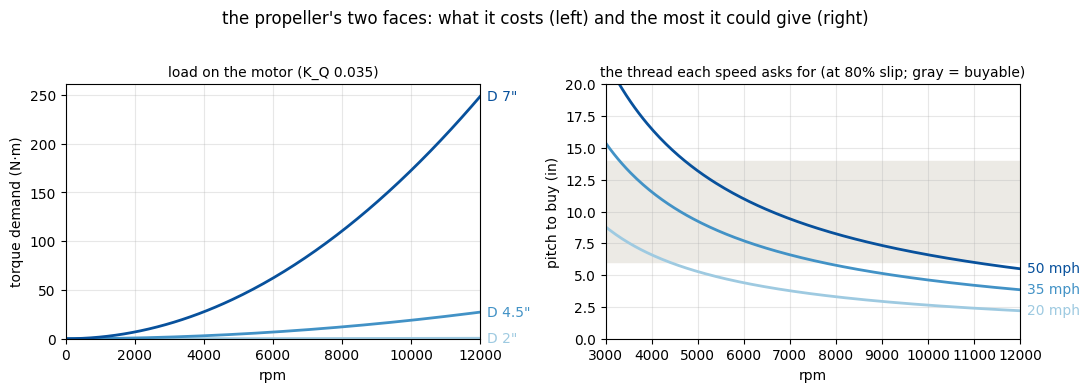

In [2]:
PROP_BOUNDS = {
    "K_Q":   (0.02, 0.05),
    "K_T":   (0.05, 0.15),
    "D_in":  (2.0, 7.0),
    "eta_p": (0.5, 0.7),
}
PROP_UNITS = {"K_Q": "-", "K_T": "-", "D_in": "in", "eta_p": "-"}
show_bounds(PROP_BOUNDS, PROP_UNITS)
SLIP_TARGET = 0.80           # run the prop at ~80% of its pitch speed
PITCH_BUYABLE = (6.0, 14.0)  # threads you can actually buy, inches
print(f"fixed: pitch is derived, not chosen -- speed x 1056 / (rpm x {SLIP_TARGET:g}), "
      f"must land in {PITCH_BUYABLE[0]:g}-{PITCH_BUYABLE[1]:g} in")

KQ_mid = sum(PROP_BOUNDS["K_Q"]) / 2
rpm = np.linspace(0, 12000, 200)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.8))
for D_in, color in zip(lo_mid_hi(PROP_BOUNDS, "D_in"), SEQ):
    Q = KQ_mid * RHO * (rpm / 60) ** 2 * (D_in * 0.0254) ** 5
    ax1.plot(rpm, Q, color=color, lw=2)
    ax1.annotate(f'D {D_in:g}"', (rpm[-1], Q[-1]),
                 xytext=(5, 0), textcoords="offset points", color=color, va="center")
rpm2 = np.linspace(3000, 12000, 200)
ax2.axhspan(*PITCH_BUYABLE, color="#eceae5", zorder=0)
for v_b, color in zip((20.0, 35.0, 50.0), SEQ):
    need = v_b * 1056 / (rpm2 * SLIP_TARGET)
    ax2.plot(rpm2, need, color=color, lw=2)
    ax2.annotate(f"{v_b:g} mph", (rpm2[-1], need[-1]),
                 xytext=(5, 0), textcoords="offset points", color=color, va="center")
ax1.set_xlabel("rpm"); ax1.set_ylabel("torque demand (N·m)")
ax1.set_title(f"load on the motor (K_Q {KQ_mid:g})", fontsize=10)
ax2.set_xlabel("rpm"); ax2.set_ylabel("pitch to buy (in)")
ax2.set_title(f"the thread each speed asks for (at {SLIP_TARGET:.0%} slip; gray = buyable)", fontsize=10)
ax1.grid(alpha=0.3); ax1.set_xlim(0, rpm[-1]); ax1.set_ylim(bottom=0); ax1.margins(x=0.15)
ax2.grid(alpha=0.3); ax2.set_xlim(rpm2[0], rpm2[-1]); ax2.set_ylim(0, 20); ax2.margins(x=0.15)
fig.suptitle("the propeller's two faces: what it costs (left) and the most it could give (right)", y=1.02)
plt.tight_layout(); plt.show()

## 3. The battery

The battery brings volts, amp-hours, and — now that the loop is closed — **its own weight**,
which the boat must carry and the water will charge for.

```text
P_elec        = V · I                                  watts drawn from the pack
C_needed      = I · (course/speed) · reserve / 0.8     the amp-hours the race makes you buy
W_batt        = C · V / e_batt                         the pack's weight (e_batt in Wh/lb)
C_rate_needed = I / (0.8 · C)                          the discharge rating it must carry
```

Only two battery numbers are **decisions**: pack voltage `V` and chemistry quality
(`e_batt`). Capacity and discharge rating are **requirements the design writes on the
shopping list** — the race sizes the amp-hours (with the usable fraction fixed at 0.8 as
policy, not a knob), and the amps size the C-rating, each guarded by one buyability limit.
Capacity and weight chase each other — a bigger pack is heavier, a heavier boat is slower,
a slower boat races longer and needs more pack — so the solve iterates them to a fixed
point. There is still no free capacity: every amp-hour is carried through the water.

input       low     high  unit
V            20       50  V
e_batt       50      100  Wh/lb
fixed: usable 0.8; rating needed = amps/(0.8 x C) <= 10C
race: 5 mi at constant drive, +30% energy reserve


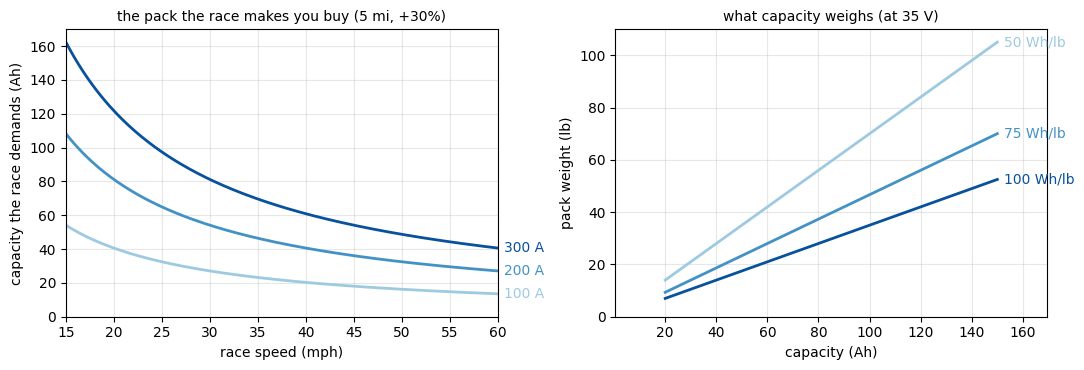

In [3]:
BATT_BOUNDS = {
    "V":      (20.0, 50.0),
    "e_batt": (50.0, 100.0),
}
BATT_UNITS = {"V": "V", "e_batt": "Wh/lb"}
show_bounds(BATT_BOUNDS, BATT_UNITS)
USABLE = 0.8            # how deep we discharge: policy, not a knob
DISCHARGE_DERATE = 0.8  # the steady draw should sit at ~80% of the pack's rating
C_RATE_MAX = 10.0       # hottest pack we consider buyable (continuous C-rating)
RACE = {"miles": 5.0, "reserve": 1.3}  # the race that sizes every pack -- EDIT to the real course
print(f"fixed: usable {USABLE:g}; rating needed = amps/({DISCHARGE_DERATE:g} x C) <= {C_RATE_MAX:g}C")
print(f"race: {RACE['miles']:g} mi at constant drive, +{RACE['reserve'] - 1:.0%} energy reserve")

V_mid = sum(BATT_BOUNDS["V"]) / 2
v_ax = np.linspace(15, 60, 200)
C_axis = np.linspace(20, 150, 100)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.8))
for I_draw, color in zip((100.0, 200.0, 300.0), SEQ):
    C_need = I_draw * RACE["miles"] / v_ax * RACE["reserve"] / USABLE
    ax1.plot(v_ax, C_need, color=color, lw=2)
    ax1.annotate(f"{I_draw:g} A", (v_ax[-1], C_need[-1]),
                 xytext=(5, 0), textcoords="offset points", color=color, va="center")
for e, color in zip(lo_mid_hi(BATT_BOUNDS, "e_batt"), SEQ):
    ax2.plot(C_axis, C_axis * V_mid / e, color=color, lw=2)
    ax2.annotate(f"{e:g} Wh/lb", (C_axis[-1], C_axis[-1] * V_mid / e),
                 xytext=(5, 0), textcoords="offset points", color=color, va="center")
ax1.set_xlabel("race speed (mph)"); ax1.set_ylabel("capacity the race demands (Ah)")
ax1.set_title(f"the pack the race makes you buy ({RACE['miles']:g} mi, +{RACE['reserve'] - 1:.0%})",
              fontsize=10)
ax2.set_xlabel("capacity (Ah)"); ax2.set_ylabel("pack weight (lb)")
ax2.set_title(f"what capacity weighs (at {V_mid:g} V)", fontsize=10)
for ax in (ax1, ax2):
    ax.grid(alpha=0.3); ax.set_ylim(bottom=0)
ax1.set_xlim(v_ax[0], v_ax[-1]); ax1.margins(x=0.15); ax2.margins(x=0.15)
plt.tight_layout(); plt.show()

## 4. The water and the weight

The water's push-back is no longer undefined — on plane it is just the all-up weight
divided by how efficiently the hull rides (its lift-to-drag ratio):

```text
W        = W_hull + W_batt + n_motors·W_motor + payload + margin    all-up weight in the water
L/D(v)   = LD0 / (1 + (v / 26)²)                            the hull rides worse the faster it goes
R_water  = W / L/D(v)                                       resistance on plane, lbf
P_tow    = R_water · speed                                  the towing bill the shaft must pay
```

`W_hull` is the **bare hull** (structure and fittings only). On top of it the boat carries
the pack (`W_batt`), the motors (`W_motor` each), a **fixed payload** we are required to
haul, and a **safety margin** — the last two are constants, set and printed below.

Lift-to-drag is **not a constant**: skin friction grows with speed², so a hull that rides
at L/D ≈ 6 just after planing is down near 2.5 when driven hard. The curve above captures
that with one quality knob, `LD0` (the hull's peak efficiency), and one fixed shape
constant (26 mph, the speed where friction has doubled the push-back) — both calibrated
against the Savitsky planing model in explore's library. Because resistance now grows with
speed on its own, the model needs **no artificial speed cap**: going fast gets expensive
for the real reason.

input       low     high  unit
W_hull       30       90  lb
LD0           5       10  -
fixed: L/D(v) = LD0 / (1 + (v/26)^2)
fixed: payload            30  lb
fixed: safety margin       5  lb


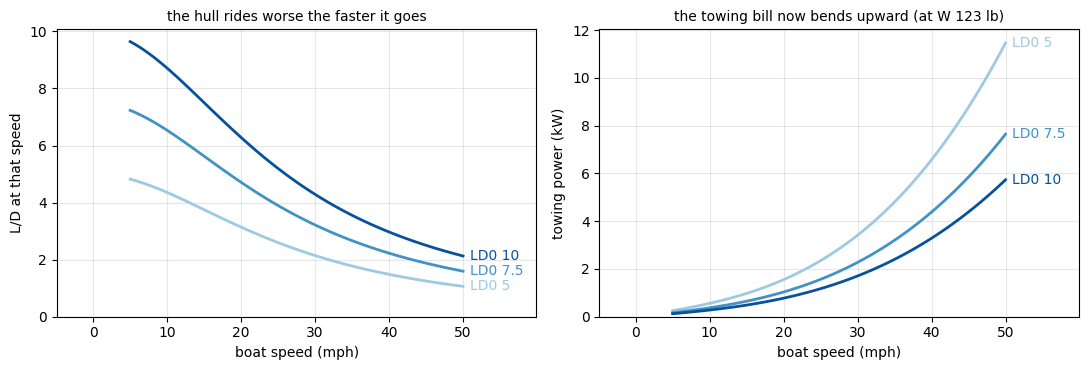

In [4]:
HULL_BOUNDS = {
    "W_hull": (30.0, 90.0),
    "LD0":    (5.0, 10.0),
}
HULL_UNITS = {"W_hull": "lb", "LD0": "-"}
show_bounds(HULL_BOUNDS, HULL_UNITS)
V_LD_HALF = 26.0  # mph at which friction has doubled the push-back (Savitsky cross-check)
print(f"fixed: L/D(v) = LD0 / (1 + (v/{V_LD_HALF:g})^2)")

W_FIXED = {"payload": 30.0, "safety margin": 5.0}  # lb, carried no matter what
W_FIXED_LB = sum(W_FIXED.values())
for name, v in W_FIXED.items():
    print(f"fixed: {name:<14}{v:>7g}  lb")

W_batt_rep = 25.0  # a representative race-sized pack, just for this chart's baseline
Wm_mid = sum(MOTOR_BOUNDS["W_motor"]) / 2
W_extra = W_batt_rep + Wm_mid + W_FIXED_LB
W_span = np.linspace(HULL_BOUNDS["W_hull"][0] + W_extra,
                     HULL_BOUNDS["W_hull"][1] + W_extra, 100)
W_mid = W_span.mean()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.8))
v = np.linspace(5, 50, 100)
for LD0, color in zip(lo_mid_hi(HULL_BOUNDS, "LD0"), SEQ):
    ax1.plot(v, LD0 / (1 + (v / V_LD_HALF) ** 2), color=color, lw=2)
    ax1.annotate(f"LD0 {LD0:g}", (v[-1], LD0 / (1 + (v[-1] / V_LD_HALF) ** 2)),
                 xytext=(5, 0), textcoords="offset points", color=color, va="center")
for LD0, color in zip(lo_mid_hi(HULL_BOUNDS, "LD0"), SEQ):
    R_N = (W_mid / (LD0 / (1 + (v / V_LD_HALF) ** 2))) * 4.4482
    ax2.plot(v, R_N * v * 0.44704 / 1000, color=color, lw=2)
    ax2.annotate(f"LD0 {LD0:g}", (v[-1], R_N[-1] * v[-1] * 0.44704 / 1000),
                 xytext=(5, 0), textcoords="offset points", color=color, va="center")
ax1.set_xlabel("boat speed (mph)"); ax1.set_ylabel("L/D at that speed")
ax1.set_title("the hull rides worse the faster it goes", fontsize=10)
ax2.set_xlabel("boat speed (mph)"); ax2.set_ylabel("towing power (kW)")
ax2.set_title(f"the towing bill now bends upward (at W {W_mid:.0f} lb)", fontsize=10)
for ax in (ax1, ax2):
    ax.grid(alpha=0.3); ax.set_ylim(bottom=0)
    ax.margins(x=0.22)
plt.tight_layout(); plt.show()

## 5. The map: how everything connects

One picture of the whole model — the ontology. Left column: every input, colored by which
purchase (or the hull) it belongs to. Middle: the quantities the equations build from them.
Right: what you actually care about. **Every arrow is one of the raw equations above.**

Worth tracing with a finger: `V` feeds **two** paths — volts buy rpm *and* weigh the pack
down. And the pack node is special: it is *sized by the race* (amps × race time), yet its
weight feeds the speed that sets the race time — the solve iterates that pair to a fixed
point.

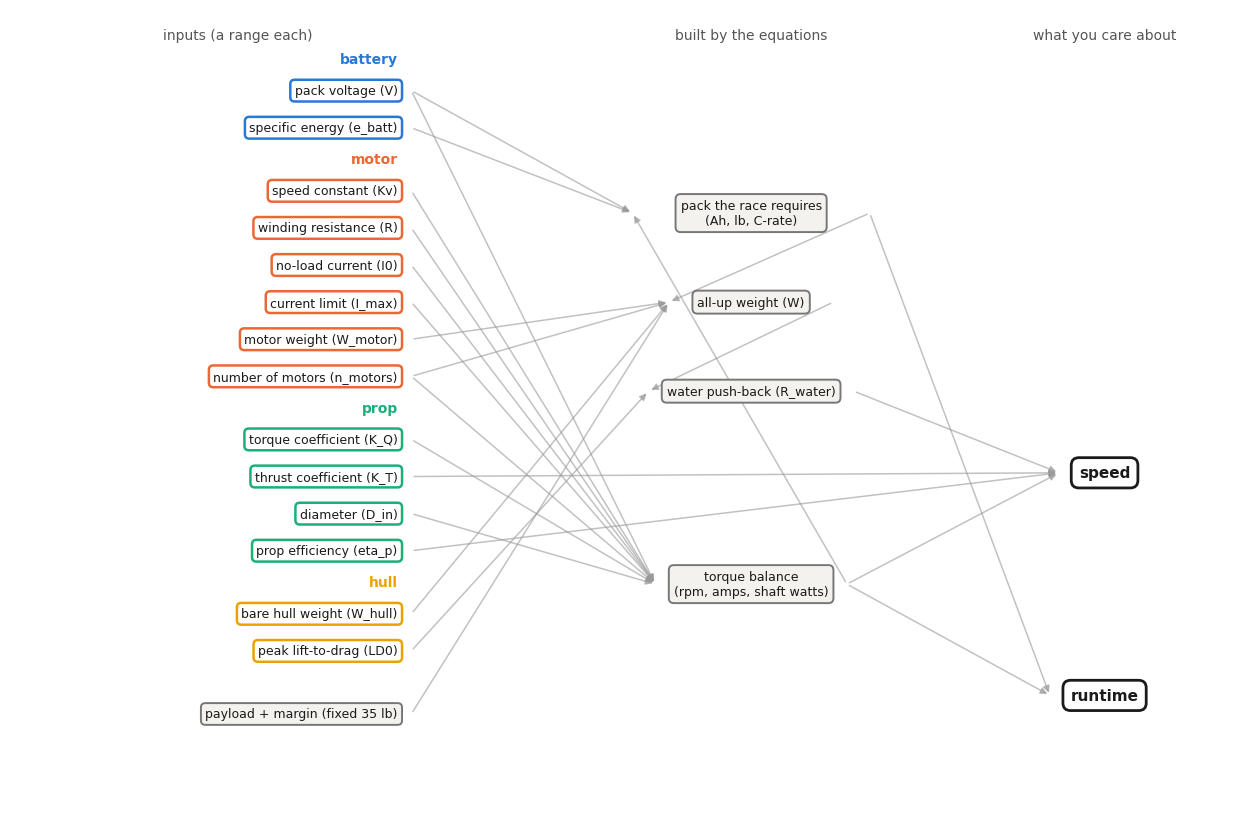

In [5]:
GROUPS = {  # validated categorical palette: identity, fixed order
    "battery": "#2a78d6", "motor": "#eb6834", "prop": "#1baf7a", "hull": "#eda100",
}
LABELS = {  # long name for every short input symbol
    "V": "pack voltage", "e_batt": "specific energy",
    "Kv": "speed constant", "R": "winding resistance", "I0": "no-load current", "I_max": "current limit",
    "K_Q": "torque coefficient", "K_T": "thrust coefficient", "D_in": "diameter", "pitch": "blade pitch", "eta_p": "prop efficiency",
    "W_hull": "bare hull weight", "LD0": "peak lift-to-drag", "W_motor": "motor weight",
    "n_motors": "number of motors",
}
INPUT_GROUPS = [
    ("battery", list(BATT_BOUNDS)),
    ("motor",   list(MOTOR_BOUNDS)),
    ("prop",    list(PROP_BOUNDS)),
    ("hull",    list(HULL_BOUNDS)),
]
TB = "torque balance\n(rpm, amps, shaft watts)"
PACK = "pack the race requires\n(Ah, lb, C-rate)"
MID_NODES = {  # name: y
    PACK: 15.0,
    "all-up weight (W)": 12.6,
    "water push-back (R_water)": 10.2,
    TB: 5.0,
}
OUT_NODES = {"speed": 8.0, "runtime": 2.0}
EDGES = [
    ("V", PACK), ("e_batt", PACK), (TB, PACK),
    ("W_hull", "all-up weight (W)"), (PACK, "all-up weight (W)"),
    ("W_motor", "all-up weight (W)"),
    ("all-up weight (W)", "water push-back (R_water)"), ("LD0", "water push-back (R_water)"),
    ("Kv", TB), ("R", TB), ("I0", TB), ("I_max", TB), ("V", TB), ("K_Q", TB), ("D_in", TB),
    ("n_motors", TB), ("n_motors", "all-up weight (W)"),
    (TB, "speed"), ("eta_p", "speed"), ("water push-back (R_water)", "speed"),
    ("K_T", "speed"),
    (TB, "runtime"), (PACK, "runtime"),
]
HW = {  # half-widths of middle/output boxes, so arrows stop at the edge
    PACK: 0.52, "all-up weight (W)": 0.36, "water push-back (R_water)": 0.45,
    TB: 0.42, "speed": 0.20, "runtime": 0.24,
}

pos = {}
y = 18.3
for gname, keys in INPUT_GROUPS:
    for k in keys:
        pos[k] = (0.0, y); y -= 1.0
    y -= 0.7  # gap between groups
FIXED_NODE = f"payload + margin (fixed {W_FIXED_LB:g} lb)"
pos[FIXED_NODE] = (0.0, y)
EDGES.append((FIXED_NODE, "all-up weight (W)"))
for name, ny in MID_NODES.items():
    pos[name] = (1.55, ny)
for name, ny in OUT_NODES.items():
    pos[name] = (3.1, ny)

fig, ax = plt.subplots(figsize=(12.5, 8.5))
for a, b in EDGES:
    (xa, ya), (xb, yb) = pos[a], pos[b]
    x_start = xa + HW.get(a, 0.06)
    ax.annotate("", xy=(xb - HW[b], yb), xytext=(x_start, ya),
                arrowprops=dict(arrowstyle="-|>", color="#999999", alpha=0.6, lw=1.1))
for gname, keys in INPUT_GROUPS:
    color = GROUPS[gname]
    ys = [pos[k][1] for k in keys]
    ax.text(0.0, max(ys) + 0.75, gname, color=color, fontsize=10, fontweight="bold", ha="right")
    for k in keys:
        ax.text(pos[k][0], pos[k][1], f"{LABELS[k]} ({k})", ha="right", va="center",
                fontsize=9, color="#1a1a19",
                bbox=dict(boxstyle="round,pad=0.35", fc="white", ec=color, lw=1.8))
ax.text(pos[FIXED_NODE][0], pos[FIXED_NODE][1], FIXED_NODE, ha="right", va="center",
        fontsize=9, color="#1a1a19",
        bbox=dict(boxstyle="round,pad=0.35", fc="#f3f2ee", ec="#777777", lw=1.4))
for name in MID_NODES:
    ax.text(*pos[name], name, ha="center", va="center", fontsize=9, color="#1a1a19",
            bbox=dict(boxstyle="round,pad=0.4", fc="#f3f2ee", ec="#777777", lw=1.4))
for name in OUT_NODES:
    ax.text(*pos[name], name, ha="center", va="center", fontsize=11, color="#1a1a19",
            fontweight="bold",
            bbox=dict(boxstyle="round,pad=0.5", fc="white", ec="#1a1a19", lw=2))
ax.text(-0.7, 19.7, "inputs (a range each)", ha="center", fontsize=10, color="#555555")
ax.text(1.55, 19.7, "built by the equations", ha="center", fontsize=10, color="#555555")
ax.text(3.1, 19.7, "what you care about", ha="center", fontsize=10, color="#555555")
ax.set_xlim(-1.7, 3.65); ax.set_ylim(-1.6, 20.5); ax.axis("off")
plt.tight_layout(); plt.show()

## 6. Bring it together

The solve, in the order the physics runs:

```text
1  torque balance    a·rpm² + b·rpm = c  ->  rpm, amps, torque (per motor)
                     a = K_Q·ρ·D⁵/3600,  b = Kt/(Kv·R),  c = Kt·(V/R − I0)
                     (if amps exceed the motor's I_max: torque pins there, rpm from the prop alone)
2  shaft power       P_shaft = n_motors · torque · 2π · rpm / 60
3  the fixed point   the race sizes the pack, the pack weighs on the boat, the weight slows
                     the boat, a slower race needs more pack -- iterate until it settles:
                       W      =  W_hull + W_batt + n_motors·W_motor + payload + margin
                       speed  from  η_p · P_shaft = R_water(speed) · speed   (cubic, one root)
                       C      =  amps · (course/speed) · reserve / 0.8
4  thrust check      n_motors·K_T·ρ·n²·D⁴ ≥ R_water(speed)  -- can the disks deliver it?
5  shopping notes    pitch = speed·1056/(rpm·0.8),  C_rate = amps/(0.8·C),  W_batt = C·V/e_batt
```

No design point is picked or printed here — the charts below show the whole space.

In [6]:
BOUNDS = {**MOTOR_BOUNDS, **PROP_BOUNDS, **BATT_BOUNDS, **HULL_BOUNDS}
UNITS = {**MOTOR_UNITS, **PROP_UNITS, **BATT_UNITS, **HULL_UNITS}
CENTER = {k: (lo + hi) / 2 for k, (lo, hi) in BOUNDS.items()}  # reference for sweeps only
CENTER["n_motors"] = 1.0  # sweeps and example charts assume a single motor

def steady_state(Kv, R, I0, I_max, W_motor, n_motors, V, K_Q, K_T, D_in, eta_p, e_batt, W_hull, LD0):
    Kt = 60 / (2 * math.pi * Kv)
    a = K_Q * RHO * (D_in * 0.0254) ** 5 / 3600
    b = Kt / (Kv * R)
    c = Kt * (V / R - I0)
    rpm = (-b + math.sqrt(b * b + 4 * a * c)) / (2 * a)
    I = (V - rpm / Kv) / R
    limited = I > I_max
    if limited:
        I = I_max
        torque = Kt * (I - I0)
        rpm = 60 * math.sqrt(torque / (K_Q * RHO * (D_in * 0.0254) ** 5))
    else:
        torque = Kt * (I - I0)
    shaft_w = n_motors * torque * 2 * math.pi * rpm / 60  # all motors together
    I_pack = n_motors * I
    cbrt = lambda x: math.copysign(abs(x) ** (1 / 3), x)
    # the race sizes the pack, the pack weighs on the speed: iterate to the fixed point
    C = 50.0
    for _ in range(25):
        W = W_hull + C * V / e_batt + n_motors * W_motor + W_FIXED_LB
        A1 = (W * 4.4482 / LD0) * 0.44704
        q = eta_p * shaft_w * V_LD_HALF ** 2 / A1
        s = math.sqrt(q * q / 4 + V_LD_HALF ** 6 / 27)
        mph = cbrt(q / 2 + s) + cbrt(q / 2 - s)
        C_new = min(I_pack * RACE["miles"] / max(mph, 2.0) * RACE["reserve"] / USABLE, 400.0)
        if abs(C_new - C) < 0.05:
            C = C_new
            break
        C = C_new
    W_batt = C * V / e_batt
    W = W_hull + W_batt + n_motors * W_motor + W_FIXED_LB
    LD_op = LD0 / (1 + (mph / V_LD_HALF) ** 2)
    pitch_need = mph * 1056 / (rpm * SLIP_TARGET)
    t_avail_lbf = n_motors * K_T * RHO * (rpm / 60) ** 2 * (D_in * 0.0254) ** 4 / 4.4482
    thrust_ok = t_avail_lbf >= W / LD_op
    c_rate_need = I_pack / (DISCHARGE_DERATE * C)
    return dict(rpm=rpm, torque=torque, I=I_pack, I_1=I, limited=limited, LD_op=LD_op,
                C=C, W_batt=W_batt, W=W, R_lbf=W / LD_op, mph=mph,
                pitch_need=pitch_need, c_rate_need=c_rate_need, shaft_w=shaft_w,
                elec_w=V * I_pack, eff=shaft_w / (V * I_pack),
                t_avail_lbf=t_avail_lbf, thrust_ok=thrust_ok,
                minutes=60 * USABLE * C / I_pack)

def solve(**over):
    return steady_state(**{**CENTER, **over})

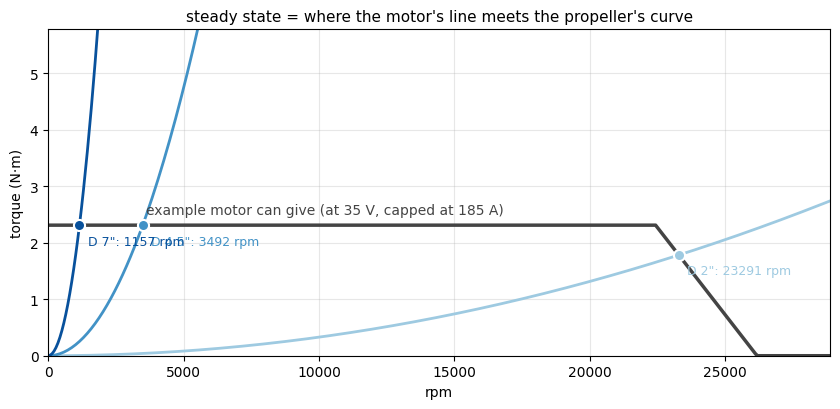

In [7]:
# the mechanism: a mid-range example motor's available torque vs the propeller's demand
Kv, R, I0, I_max, V = (CENTER[k] for k in ("Kv", "R", "I0", "I_max", "V"))
Kt = 60 / (2 * math.pi * Kv)
rpm_free = Kv * V
rpm_axis = np.linspace(1, 1.1 * rpm_free, 400)
I_avail = np.clip((V - rpm_axis / Kv) / R, 0, I_max)
Q_motor = np.maximum(Kt * (I_avail - I0), 0)

fig, ax = plt.subplots(figsize=(8.5, 4.2))
ax.plot(rpm_axis, Q_motor, color="#444444", lw=2.5)
ax.annotate(f"example motor can give (at {V:g} V, capped at {I_max:g} A)",
            (rpm_axis[len(rpm_axis) // 8], Kt * (I_max - I0)),
            xytext=(0, 8), textcoords="offset points", color="#444444")
for D_in, color in zip(lo_mid_hi(PROP_BOUNDS, "D_in"), SEQ):
    Q_prop = CENTER["K_Q"] * RHO * (rpm_axis / 60) ** 2 * (D_in * 0.0254) ** 5
    ax.plot(rpm_axis, Q_prop, color=color, lw=2)
    op = solve(D_in=D_in)
    ax.plot(op["rpm"], op["torque"], "o", color=color, ms=8,
            markeredgecolor="white", markeredgewidth=1.5, zorder=5)
    ax.annotate(f'D {D_in:g}": {op["rpm"]:.0f} rpm', (op["rpm"], op["torque"]),
                xytext=(6, -14), textcoords="offset points", color=color, fontsize=9)
ax.set_xlabel("rpm"); ax.set_ylabel("torque (N·m)")
ax.set_title("steady state = where the motor's line meets the propeller's curve", fontsize=11)
ax.set_xlim(0, rpm_axis[-1]); ax.set_ylim(0, 2.5 * Kt * (I_max - I0))
ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

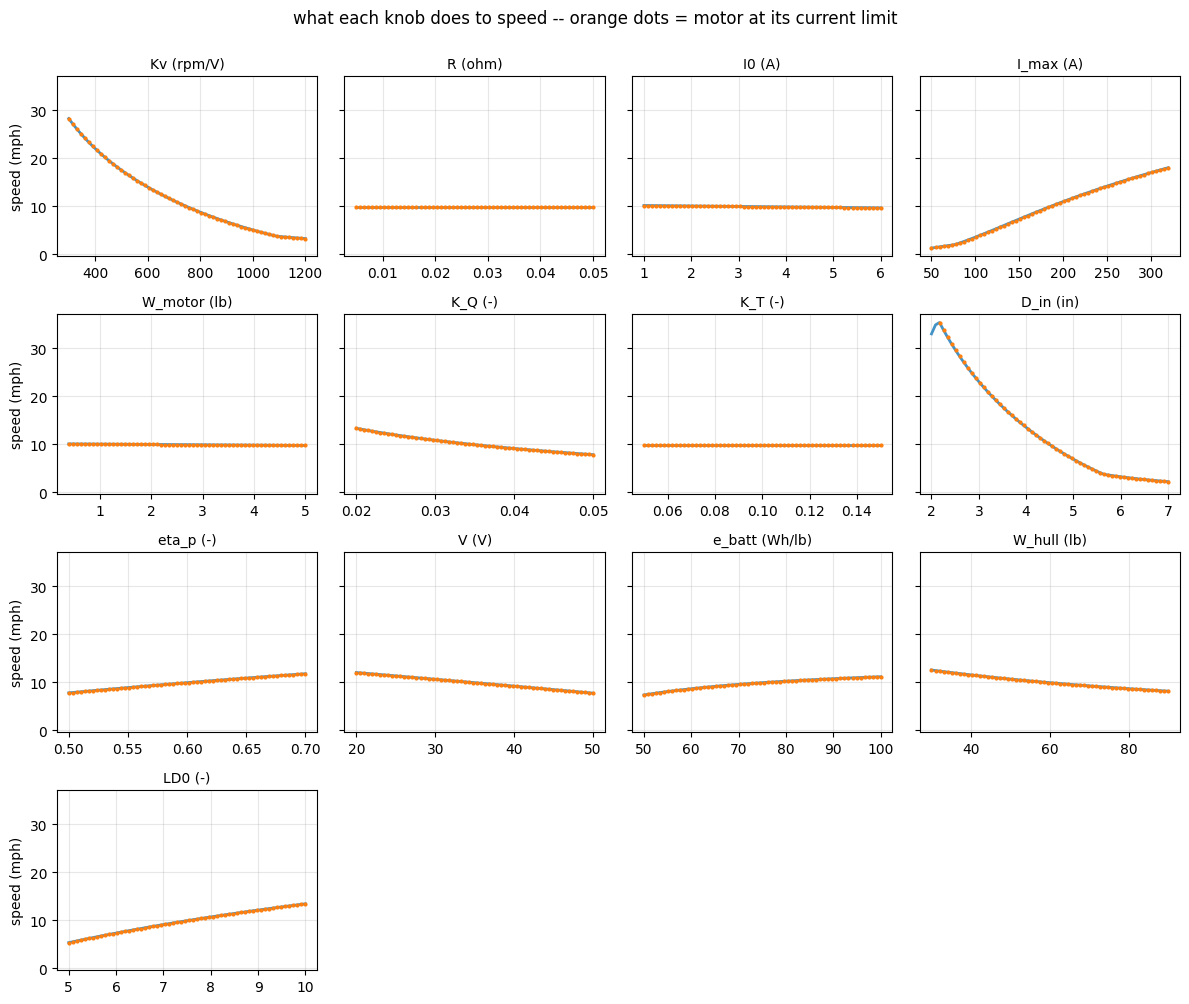

In [8]:
# one panel per input: sweep it across its range, everything else held mid-range (one motor)
SWEEP_KEYS = [k for k in BOUNDS if k != "n_motors"]
fig, axes = plt.subplots(4, 4, figsize=(12, 10), sharey=True)
for key, ax in zip(SWEEP_KEYS, axes.flat):
    lo, hi = BOUNDS[key]
    xs = np.linspace(lo, hi, 60)
    res = [solve(**{key: x}) for x in xs]
    ys = np.array([r["mph"] for r in res])
    lim = np.array([r["limited"] for r in res])
    ax.plot(xs, ys, color="#4292c6", lw=2)
    if lim.any():
        ax.plot(xs[lim], ys[lim], ".", color="tab:orange", ms=4)
    ax.set_title(f"{key} ({UNITS[key]})", fontsize=10)
    ax.grid(alpha=0.3)
for ax in axes.flat[len(SWEEP_KEYS):]:
    ax.axis("off")
for ax in axes[:, 0]:
    ax.set_ylabel("speed (mph)")
fig.suptitle("what each knob does to speed -- orange dots = motor at its current limit", y=1.0)
plt.tight_layout(); plt.show()

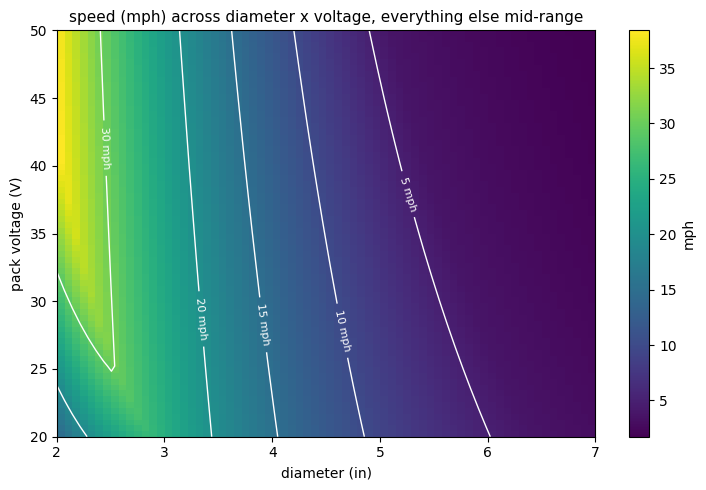

across this map the design asks you to buy pitch between 1.4 and 4.6 in (buyable: 6-14)


In [9]:
# the two purchase knobs with the widest leverage left: diameter x pack voltage
D_axis = np.linspace(*PROP_BOUNDS["D_in"], 70)
V_axis = np.linspace(*BATT_BOUNDS["V"], 70)
res = [[solve(D_in=D, V=v) for D in D_axis] for v in V_axis]
speed = np.array([[r["mph"] for r in row] for row in res])

fig, ax = plt.subplots(figsize=(7.5, 5))
im = ax.imshow(speed, origin="lower", aspect="auto", cmap="viridis",
               extent=[D_axis[0], D_axis[-1], V_axis[0], V_axis[-1]])
levels = [lv for lv in (5, 10, 15, 20, 30, 40, 50) if speed.min() < lv < speed.max()]
if levels:
    cs = ax.contour(D_axis, V_axis, speed, levels=levels, colors="white", linewidths=1)
    ax.clabel(cs, fmt="%g mph", fontsize=8)
ax.set_xlabel("diameter (in)"); ax.set_ylabel("pack voltage (V)")
ax.set_title("speed (mph) across diameter x voltage, everything else mid-range", fontsize=11)
fig.colorbar(im, ax=ax, label="mph")
plt.tight_layout(); plt.show()

pitchg = np.array([[r["pitch_need"] for r in row] for row in res])
print(f"across this map the design asks you to buy pitch between "
      f"{pitchg.min():.1f} and {pitchg.max():.1f} in "
      f"(buyable: {PITCH_BUYABLE[0]:g}-{PITCH_BUYABLE[1]:g})")

## 7. How the variables move together

The map (section 5) shows *structure*; this shows *strength*. Sample every input uniformly
across its range — thousands of whole-model solves scattered through the input space — and
correlate each input with each output. Deep red: raising the input raises the output.
Deep blue: raising it lowers the output. Near white: it barely matters there.

This is the shopping cheat-sheet: a column tells you which knobs actually move that
outcome, and the `V` row shows its double life from the map playing out.

speed (mph)    across the whole space:  p10    1.8   median   12.3   p90   33.6
battery needed (Ah) across the whole space:  p10   49.8   median  165.7   p90  400.0
amps (A)       across the whole space:  p10   89.5   median  231.0   p90  513.4
weight (lb)    across the whole space:  p10  112.3   median  177.1   p90  331.4


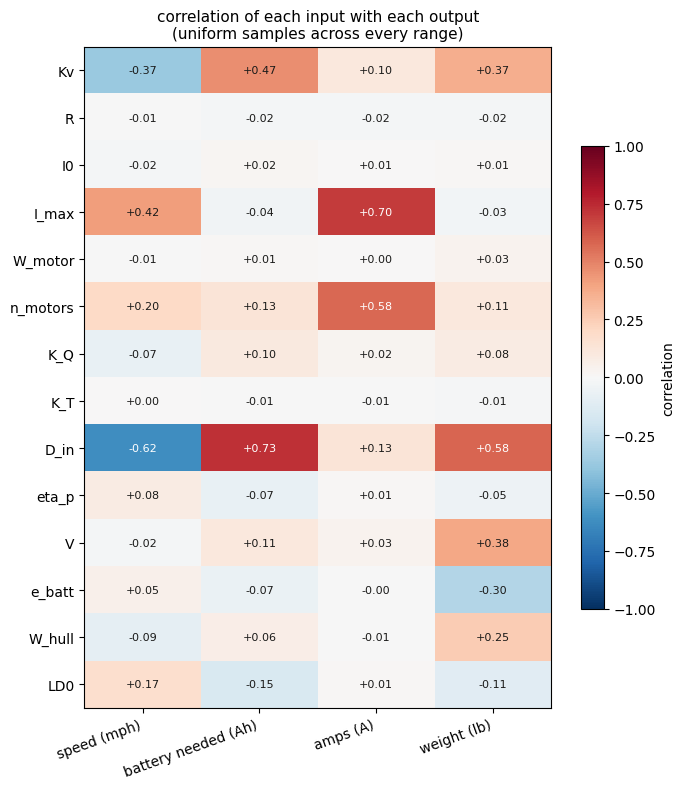

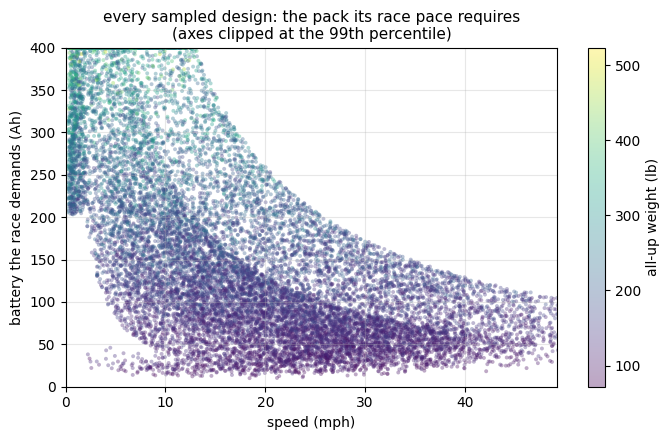

In [10]:
rng = np.random.default_rng(0)
N = 20000
samples = {k: rng.uniform(lo, hi, N) for k, (lo, hi) in BOUNDS.items()}
samples["n_motors"] = rng.integers(1, 3, N).astype(float)  # a discrete choice: one or two
runs = [steady_state(**{k: samples[k][i] for k in BOUNDS}) for i in range(N)]
OUT = {"speed (mph)": "mph", "battery needed (Ah)": "C", "amps (A)": "I", "weight (lb)": "W"}
outs = {label: np.array([r[key] for r in runs]) for label, key in OUT.items()}

for label, arr in outs.items():
    p10, p50, p90 = np.percentile(arr, [10, 50, 90])
    print(f"{label:<14} across the whole space:  p10 {p10:6.1f}   median {p50:6.1f}   p90 {p90:6.1f}")

corr = np.array([[np.corrcoef(samples[k], arr)[0, 1] for arr in outs.values()]
                 for k in BOUNDS])
fig, ax = plt.subplots(figsize=(7, 8))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1, aspect="auto")
ax.set_xticks(range(len(outs))); ax.set_xticklabels(outs.keys(), rotation=20, ha="right")
ax.set_yticks(range(len(BOUNDS))); ax.set_yticklabels(BOUNDS.keys())
for i in range(len(BOUNDS)):
    for j in range(len(outs)):
        ax.text(j, i, f"{corr[i, j]:+.2f}", ha="center", va="center", fontsize=8,
                color="white" if abs(corr[i, j]) > 0.55 else "#1a1a19")
ax.set_title("correlation of each input with each output\n(uniform samples across every range)",
             fontsize=11)
fig.colorbar(im, ax=ax, label="correlation", shrink=0.7)
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(figsize=(7, 4.5))
sc = ax.scatter(outs["speed (mph)"], outs["battery needed (Ah)"], c=outs["weight (lb)"],
                cmap="viridis", s=8, alpha=0.35, edgecolors="none")
ax.set_xlim(0, np.percentile(outs["speed (mph)"], 99))
ax.set_ylim(0, np.percentile(outs["battery needed (Ah)"], 99))
ax.set_xlabel("speed (mph)"); ax.set_ylabel("battery the race demands (Ah)")
ax.set_title("every sampled design: the pack its race pace requires\n(axes clipped at the 99th percentile)", fontsize=11)
ax.grid(alpha=0.3)
fig.colorbar(sc, ax=ax, label="all-up weight (lb)")
plt.tight_layout(); plt.show()

## 8. Conclusions: the valid space and the ideal space

Two different "good"s, kept apart on purpose:

- **Valid** = meets the requirements (edit them below) *and* stays where the model's own
  assumptions hold. The race itself needs no check anymore: every design's pack is *sized
  to* the race plus reserve by construction — what's checked is that the shopping notes are
  buyable (a real pitch thread, a pack rating under the ceiling) and that the physics is
  honest (thrust covers push-back, the motor isn't mostly a heater).
- **Ideal** = among the valid designs, simply the **fastest** — at constant drive, race
  time is just `course / speed`, so best speed *is* best race time.

Everything here is recomputed from the samples: change a requirement, a sanity bound, or
any input range above, re-run, and the conclusions reshape themselves.

In [11]:
# what we demand of the boat (edit freely), and where the model can be trusted
REQS = {"min_speed_mph": 15.0, "max_weight_lb": 160.0}
SANITY = {"min_motor_eff": 0.5}

eff_s = np.array([r["eff"] for r in runs])
thrust_s = np.array([r["thrust_ok"] for r in runs])
crate_s = np.array([r["c_rate_need"] for r in runs])
pitch_s = np.array([r["pitch_need"] for r in runs])
spd = outs["speed (mph)"]; cap_s = outs["battery needed (Ah)"]
wt = outs["weight (lb)"]; amps = outs["amps (A)"]

checks = {
    f"speed >= {REQS['min_speed_mph']:g} mph  (fast enough to bother)": spd >= REQS["min_speed_mph"],
    f"weight <= {REQS['max_weight_lb']:g} lb  (still a small boat)": wt <= REQS["max_weight_lb"],
    f"motor eff >= {SANITY['min_motor_eff']:g}  (less heat than shaft power)": eff_s >= SANITY["min_motor_eff"],
    "prop thrust covers the push-back  (the K_T ceiling)": thrust_s,
    f"pack rating needed <= {C_RATE_MAX:g}C  (a pack you can actually buy)": crate_s <= C_RATE_MAX,
    f"pitch needed in {PITCH_BUYABLE[0]:g}-{PITCH_BUYABLE[1]:g} in  (a thread you can actually buy)":
        (pitch_s >= PITCH_BUYABLE[0]) & (pitch_s <= PITCH_BUYABLE[1]),
}
valid = np.ones(N, dtype=bool)
w = max(len(k) for k in checks)
for name, m in checks.items():
    print(f"{name:<{w}}   passes {m.mean():6.1%} alone")
    valid &= m
print()
print(f"all {len(checks)} at once -> the VALID space: {valid.mean():.1%} of samples ({valid.sum()} designs)")
print(f"(the race needs no check: every pack is sized to {RACE['miles']:g} mi "
      f"+ {RACE['reserve'] - 1:.0%} reserve by construction)")

speed >= 15 mph  (fast enough to bother)                   passes  43.4% alone
weight <= 160 lb  (still a small boat)                     passes  40.9% alone
motor eff >= 0.5  (less heat than shaft power)             passes  16.7% alone
prop thrust covers the push-back  (the K_T ceiling)        passes  15.0% alone
pack rating needed <= 10C  (a pack you can actually buy)   passes 100.0% alone
pitch needed in 6-14 in  (a thread you can actually buy)   passes  17.2% alone

all 6 at once -> the VALID space: 0.8% of samples (154 designs)
(the race needs no check: every pack is sized to 5 mi + 30% reserve by construction)


motor count among valid designs: 20% single, 80% twin


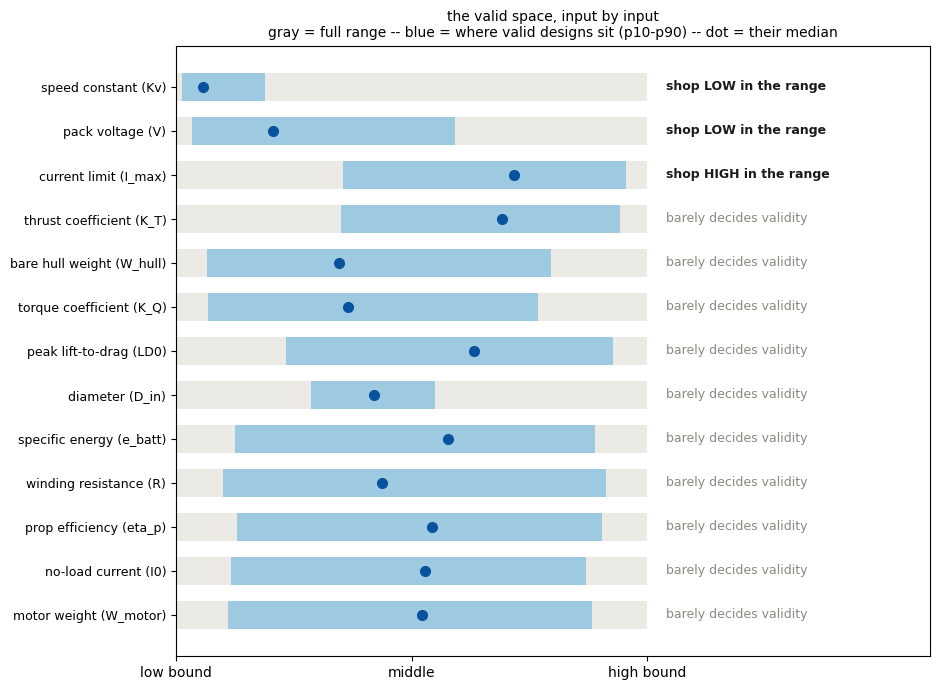

In [12]:
# where the valid designs sit inside each input's range -- the shopping directions
if not valid.any():
    print("no valid designs: loosen REQS/SANITY or widen the input ranges, then re-run")
else:
    two = samples["n_motors"][valid] > 1.5
    print(f"motor count among valid designs: {1 - two.mean():.0%} single, {two.mean():.0%} twin")
    rows = []
    for k in BOUNDS:
        if k == "n_motors":
            continue
        lo, hi = BOUNDS[k]
        p = (samples[k][valid] - lo) / (hi - lo)
        q10, q50, q90 = np.percentile(p, [10, 50, 90])
        rows.append((k, q10, q50, q90, q50 - 0.5))
    rows.sort(key=lambda r: abs(r[4]), reverse=True)

    fig, ax = plt.subplots(figsize=(9.5, 7))
    for i, (k, q10, q50, q90, shift) in enumerate(rows):
        y = len(rows) - 1 - i
        ax.barh(y, 1.0, left=0, height=0.62, color="#eceae5", zorder=1)
        ax.barh(y, q90 - q10, left=q10, height=0.62, color="#9ecae1", zorder=2)
        ax.plot(q50, y, "o", color="#08519c", ms=7, zorder=3)
        if abs(shift) >= 0.2:
            note = "shop HIGH in the range" if shift > 0 else "shop LOW in the range"
            ax.text(1.04, y, note, va="center", fontsize=9, color="#1a1a19", fontweight="bold")
        else:
            ax.text(1.04, y, "barely decides validity", va="center", fontsize=9, color="#8a887f")
    ax.set_yticks([len(rows) - 1 - i for i in range(len(rows))])
    ax.set_yticklabels([f"{LABELS[k]} ({k})" for k, *_ in rows], fontsize=9)
    ax.set_xlim(0, 1.6); ax.set_xticks([0, 0.5, 1.0])
    ax.set_xticklabels(["low bound", "middle", "high bound"])
    ax.set_title("the valid space, input by input\ngray = full range -- blue = where valid designs sit (p10-p90) -- dot = their median",
                 fontsize=10)
    plt.tight_layout(); plt.show()

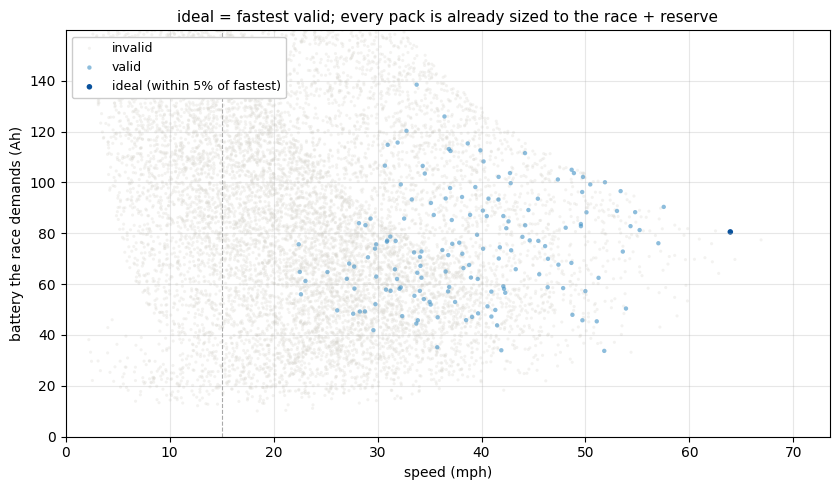

top 3 fastest valid (race = 5 mi at constant drive):
         speed   race time   pack to buy    weight
      63.9 mph     4.7 min         81 Ah    123 lb
      57.5 mph     5.2 min         90 Ah    129 lb
      57.0 mph     5.3 min         76 Ah    143 lb


In [13]:
# the ideal space: fastest valid -- and the pack each speed makes you buy
if valid.any():
    fast_cut = 0.95 * spd[valid].max()
    ideal_m = valid & (spd >= fast_cut)

    fig, ax = plt.subplots(figsize=(8.5, 5))
    ax.scatter(spd[~valid], cap_s[~valid], s=5, color="#d8d6cf", alpha=0.3, edgecolors="none", label="invalid")
    ax.scatter(spd[valid], cap_s[valid], s=10, color="#4292c6", alpha=0.6, edgecolors="none", label="valid")
    ax.scatter(spd[ideal_m], cap_s[ideal_m], s=16, color="#08519c", edgecolors="none",
               label="ideal (within 5% of fastest)")
    ax.axvline(REQS["min_speed_mph"], color="#aaaaaa", lw=0.8, ls="--")
    ax.set_xlim(0, spd[valid].max() * 1.15)
    ax.set_ylim(0, np.percentile(cap_s[valid], 99) * 1.3)
    ax.set_xlabel("speed (mph)"); ax.set_ylabel("battery the race demands (Ah)")
    ax.set_title("ideal = fastest valid; every pack is already sized to the race + reserve", fontsize=11)
    ax.legend(loc="upper left", fontsize=9, framealpha=1); ax.grid(alpha=0.3)
    plt.tight_layout(); plt.show()

    top = np.argsort(-np.where(valid, spd, -np.inf))[:3]
    print(f"top 3 fastest valid (race = {RACE['miles']:g} mi at constant drive):")
    print(f"{'':>4}{'speed':>10}{'race time':>12}{'pack to buy':>14}{'weight':>10}")
    for i in top:
        print(f"{'':>4}{spd[i]:>6.1f} mph{60 * RACE['miles'] / spd[i]:>8.1f} min"
              f"{cap_s[i]:>11.0f} Ah{wt[i]:>7.0f} lb")

## 9. What's actually out there: the SSS catalog

Every winding of every SSS motor on the supplier sheet (`sss_motors.csv`), pushed through
the **exact same model and the exact same validity checks** as section 8. The motor's
numbers (`Kv`, `R`, `I0`, `I_max`, and its weight) come off the sheet instead of a range;
prop, battery and hull are sampled from their ranges as before, with two reality rules the
sheet adds:

- pack voltage is clamped to the winding's `v_max` (you'd buy a pack the motor can take), and
- combos that spin past the winding's `max_rpm` are invalid.

A **combo** is one winding paired with one sampled prop + battery + hull; the combo is
**valid** if it passes every section-8 check plus the sheet's `max_rpm`. So "valid %"
is each winding's *room to work with* — the share of the prop/battery/hull space that
keeps it inside the valid space. The winding that tops this table is not "the fastest
motor"; it is the **most forgiving** one — the one that stays valid with the widest
variety of props, batteries and hulls. Which designs are actually *best* is section 10's
job (the ideal set), and the two answers need not be the same winding.

In [14]:
import csv

with open("sss_motors.csv") as f:
    CATALOG = [dict(name=f"{r['motor']} {r['winding']}", Kv=float(r["kv_rpm_per_v"]),
                    R=float(r["r_ohm"]), I0=float(r["i0_a_at_11v"]), I_max=float(r["i_max_a"]),
                    v_max=float(r["v_max_v"]), max_rpm=float(r["max_rpm"]),
                    W_motor=float(r["weight_g"]) / 453.592)
               for r in csv.DictReader(f)]
print(f"{len(CATALOG)} windings on the SSS sheet")

NON_MOTOR = [k for k in BOUNDS if k not in MOTOR_BOUNDS]
Nm = 2000
rng2 = np.random.default_rng(1)
sub = {k: rng2.uniform(*BOUNDS[k], Nm) for k in NON_MOTOR}
sub["n_motors"] = rng2.integers(1, 3, Nm).astype(float)

def run_winding(m):
    res = []
    for i in range(Nm):
        p = {k: sub[k][i] for k in NON_MOTOR}
        p["n_motors"] = sub["n_motors"][i]
        p["V"] = min(p["V"], m["v_max"])  # buy a pack the winding can take
        r = steady_state(Kv=m["Kv"], R=m["R"], I0=m["I0"], I_max=m["I_max"], W_motor=m["W_motor"], **p)
        r["ok"] = (r["mph"] >= REQS["min_speed_mph"]
                   and r["W"] <= REQS["max_weight_lb"] and r["eff"] >= SANITY["min_motor_eff"]
                   and PITCH_BUYABLE[0] <= r["pitch_need"] <= PITCH_BUYABLE[1]
                   and r["thrust_ok"] and r["c_rate_need"] <= C_RATE_MAX
                   and r["rpm"] <= m["max_rpm"])
        r["inputs"] = p  # the non-motor inputs actually used (V after the v_max clamp)
        res.append(r)
    return res

summary, CAT_VALID = [], []
for m in CATALOG:
    res = run_winding(m)
    ok = [r for r in res if r["ok"]]
    for r in ok:
        CAT_VALID.append(dict(name=m["name"], mph=r["mph"], minutes=r["minutes"], inputs=r["inputs"]))
    summary.append(dict(m=m, frac=len(ok) / Nm,
                        best_mph=max((r["mph"] for r in ok), default=float("nan")),
                        best_min=max((r["minutes"] for r in ok), default=float("nan"))))
summary.sort(key=lambda s: -s["frac"])

n_zero = sum(1 for s in summary if s["frac"] == 0)
print(f"windings with no valid combo at all: {n_zero} of {len(summary)}")
print()
print(f"{'winding':<24}{'Kv':>6}{'v_max':>7}{'I_max':>7}   {'valid':>6}  {'best mph':>9}{'best min':>9}")
for s in summary[:12]:
    m = s["m"]
    print(f"{m['name']:<24}{m['Kv']:>6.0f}{m['v_max']:>7.0f}{m['I_max']:>7.0f}   "
          f"{s['frac']:>6.1%}  {s['best_mph']:>9.1f}{s['best_min']:>9.1f}")
print()
print(f"(for scale: random motors drawn from the section-1 ranges are {valid.mean():.1%} valid)")

263 windings on the SSS sheet


windings with no valid combo at all: 214 of 263

winding                     Kv  v_max  I_max    valid   best mph best min
SSS 56154-V2 12Y           165    150    133    20.3%       53.5     25.7
SSS 56154-V2 11Y           180    138    145    19.5%       53.1     24.3
SSS 56154-V2 10Y           200    125    160    18.9%       54.8     22.0
SSS 56154-V2 9Y            220    112    178    16.8%       56.9     20.2
SSS 56154-V2 8Y            250     99    202    14.7%       62.8     20.9
SSS 56133-V2 11Y           200    170    100    13.9%       52.4     24.0
SSS 56154-V2 7Y            280     88    227    13.4%       64.0     17.4
SSS 56133-V2 10Y           230    155    108    11.2%       52.4     25.8
SSS 56154-V2 6Y            330     75    266     9.9%       63.1     16.7
SSS 56123-V1 12Y           230    155     95     9.4%       49.1     25.2
SSS 56123-V2 12Y           230    155     95     9.4%       49.0     25.2
SSS 56133-V2 9Y            270    135    128     8.2%       51.

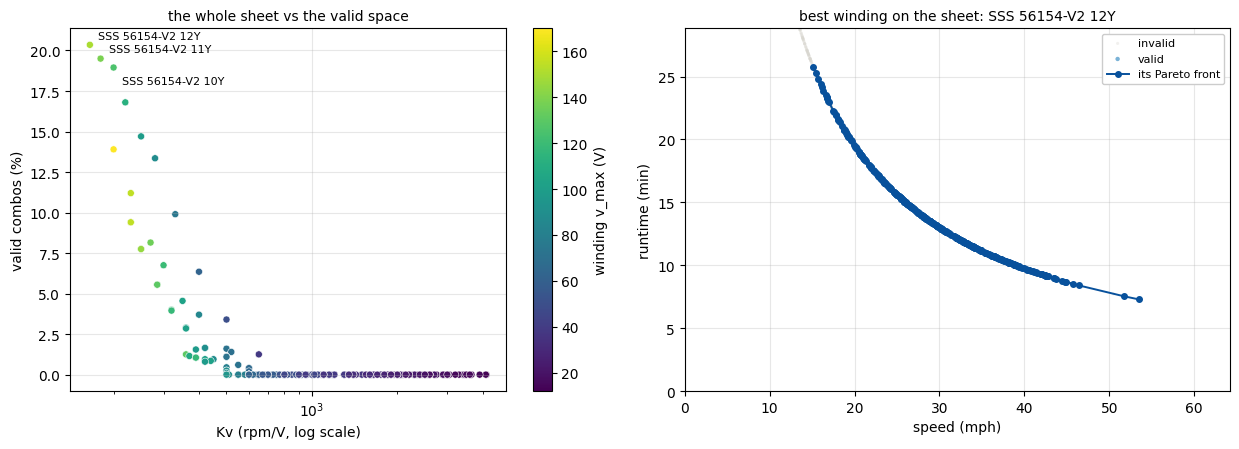

In [15]:
# the catalog in one picture, and what the best winding on the sheet can actually do
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12.5, 4.6))
kv = np.array([s["m"]["Kv"] for s in summary])
fr = np.array([s["frac"] for s in summary])
vm = np.array([s["m"]["v_max"] for s in summary])
sc = ax1.scatter(kv, fr * 100, c=vm, cmap="viridis", s=26, edgecolors="white", linewidths=0.4)
ax1.set_xscale("log")
for s, off in zip(summary[:3], [(6, 4), (6, 5), (6, -12)]):
    ax1.annotate(s["m"]["name"], (s["m"]["Kv"], s["frac"] * 100),
                 xytext=off, textcoords="offset points", fontsize=8)
ax1.set_xlabel("Kv (rpm/V, log scale)"); ax1.set_ylabel("valid combos (%)")
ax1.set_title("the whole sheet vs the valid space", fontsize=10)
ax1.grid(alpha=0.3)
fig.colorbar(sc, ax=ax1, label="winding v_max (V)")

best = summary[0]["m"]
res = run_winding(best)
mphs = np.array([r["mph"] for r in res]); mins = np.array([r["minutes"] for r in res])
okm = np.array([r["ok"] for r in res])
ax2.scatter(mphs[~okm], mins[~okm], s=5, color="#d8d6cf", alpha=0.35, edgecolors="none", label="invalid")
if okm.any():
    ax2.scatter(mphs[okm], mins[okm], s=10, color="#4292c6", alpha=0.7, edgecolors="none", label="valid")
    vi2 = np.where(okm)[0]
    order2 = vi2[np.argsort(-mphs[vi2])]
    front2, brt = [], -np.inf
    for i in order2:
        if mins[i] > brt:
            front2.append(i); brt = mins[i]
    ax2.plot(mphs[front2], mins[front2], "-o", color="#08519c", ms=4, lw=1.4, label="its Pareto front")
    ax2.set_ylim(0, mins[okm].max() * 1.12)
ax2.set_xlim(0, (mphs[okm].max() if okm.any() else mphs.max()) * 1.2)
ax2.set_xlabel("speed (mph)"); ax2.set_ylabel("runtime (min)")
ax2.set_title(f"best winding on the sheet: {best['name']}", fontsize=10)
ax2.legend(loc="upper right", fontsize=8, framealpha=1)
ax2.grid(alpha=0.3)
plt.tight_layout(); plt.show()

## 10. Are the ideal designs pressed against our bounds?

Every range in this notebook is a guess with a low end and a high end. If the ideal
designs pile up against one end of a range, **that bound — not the physics — is doing the
choosing**: widen it if it was arbitrary, or firm it up if it's a real limit (and then
"buy the bound" is the actual conclusion).

Ideal here = the **fastest valid combos** (the top 50, pooled across every SSS winding) —
the best race pace, using only motors we can actually buy.

5053 valid catalog combos -> ideal = the 50 fastest (64.7 down to 56.4 mph; best race 4.6 min)
windings in the ideal set: SSS 56154-V2 4Y (11), SSS 56154-V2 5Y (9), SSS 56154-V2 7Y (9), SSS 56154-V2 3Y (8), SSS 56154-V2 6Y (8), SSS 56154-V2 8Y (3) ...
motor count in the ideal set: 0% single, 100% twin



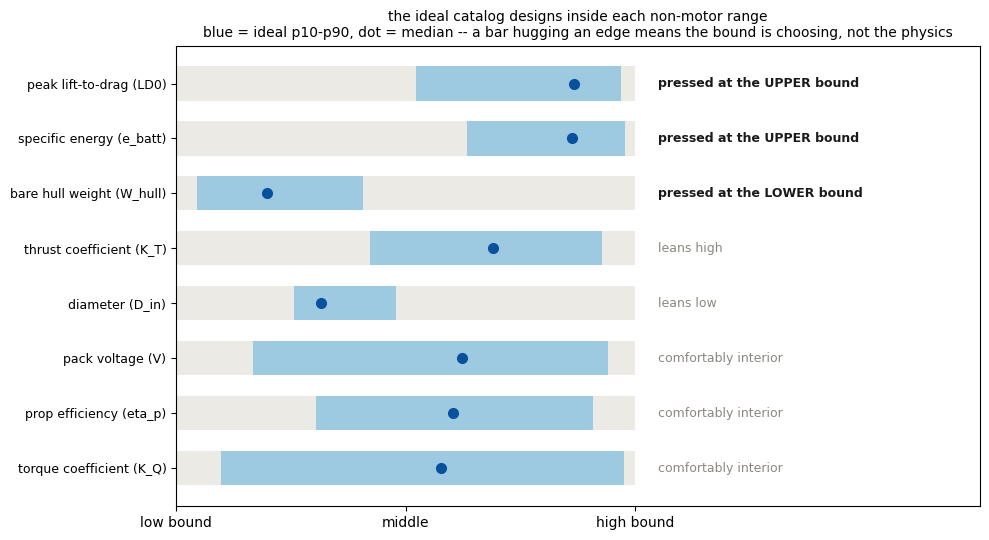


peak lift-to-drag (LD0): ideal median 9.34 - -> hugging the upper bound (5..10): widen it if it was a guess, or buy the bound if it's real
specific energy (e_batt): ideal median 93.1 Wh/lb -> hugging the upper bound (50..100): widen it if it was a guess, or buy the bound if it's real
bare hull weight (W_hull): ideal median 41.9 lb -> hugging the lower bound (30..90): widen it if it was a guess, or buy the bound if it's real


In [16]:
from collections import Counter

mph_a = np.array([d["mph"] for d in CAT_VALID])
best_mph = mph_a.max()
keep = max(50, int((mph_a >= 0.95 * best_mph).sum()))  # a statistically useful ideal set
order = np.argsort(-mph_a)[:keep]
IDEAL = [CAT_VALID[i] for i in order]
slowest_ideal = mph_a[order[-1]]
print(f"{len(CAT_VALID)} valid catalog combos -> ideal = the {len(IDEAL)} fastest "
      f"({best_mph:.1f} down to {slowest_ideal:.1f} mph; best race {60 * RACE['miles'] / best_mph:.1f} min)")
mix = Counter(d["name"] for d in IDEAL).most_common()
print("windings in the ideal set: " + ", ".join(f"{n} ({c})" for n, c in mix[:6])
      + (" ..." if len(mix) > 6 else ""))
two_i = np.array([d["inputs"]["n_motors"] for d in IDEAL]) > 1.5
print(f"motor count in the ideal set: {1 - two_i.mean():.0%} single, {two_i.mean():.0%} twin")
print()

rows = []
for k in NON_MOTOR:
    lo, hi = BOUNDS[k]
    pos = np.array([(d["inputs"][k] - lo) / (hi - lo) for d in IDEAL])
    q10, q50, q90 = np.percentile(pos, [10, 50, 90])
    rows.append((k, q10, q50, q90))
rows.sort(key=lambda r: abs(r[2] - 0.5), reverse=True)

def verdict(q50):
    if q50 >= 0.8: return "pressed at the UPPER bound", True
    if q50 <= 0.2: return "pressed at the LOWER bound", True
    if q50 >= 0.65: return "leans high", False
    if q50 <= 0.35: return "leans low", False
    return "comfortably interior", False

fig, ax = plt.subplots(figsize=(10, 5.5))
for i, (k, q10, q50, q90) in enumerate(rows):
    y = len(rows) - 1 - i
    ax.barh(y, 1.0, left=0, height=0.62, color="#eceae5", zorder=1)
    ax.barh(y, q90 - q10, left=q10, height=0.62, color="#9ecae1", zorder=2)
    ax.plot(q50, y, "o", color="#08519c", ms=7, zorder=3)
    text, pinned = verdict(q50)
    ax.text(1.05, y, text, va="center", fontsize=9,
            color="#1a1a19" if pinned else "#8a887f",
            fontweight="bold" if pinned else "normal")
ax.set_yticks([len(rows) - 1 - i for i in range(len(rows))])
ax.set_yticklabels([f"{LABELS[k]} ({k})" for k, *_ in rows], fontsize=9)
ax.set_xlim(0, 1.75); ax.set_xticks([0, 0.5, 1.0])
ax.set_xticklabels(["low bound", "middle", "high bound"])
ax.set_title("the ideal catalog designs inside each non-motor range\nblue = ideal p10-p90, dot = median -- a bar hugging an edge means the bound is choosing, not the physics",
             fontsize=10)
plt.tight_layout(); plt.show()

print()
pinned_any = False
for k, q10, q50, q90 in rows:
    text, pinned = verdict(q50)
    if pinned:
        pinned_any = True
        lo, hi = BOUNDS[k]
        med_val = lo + q50 * (hi - lo)
        side = "upper" if q50 >= 0.8 else "lower"
        print(f"{LABELS[k]} ({k}): ideal median {med_val:.3g} {UNITS[k]} -> hugging the {side} "
              f"bound ({lo:g}..{hi:g}): widen it if it was a guess, or buy the bound if it's real")
if not pinned_any:
    print("no input is pressed against a bound: the ranges are wide enough that the physics is choosing")

In [17]:
# the shopping lists: three concrete ideal designs -- all race-pace, differing in cost of carry
scores = []
for d in IDEAL:
    m = next(c for c in CATALOG if c["name"] == d["name"])
    r = steady_state(Kv=m["Kv"], R=m["R"], I0=m["I0"], I_max=m["I_max"],
                     W_motor=m["W_motor"], **d["inputs"])
    scores.append((d, m, r))
PICK_IDX = {
    "fastest ideal": int(np.argmax([r["mph"] for d, m, r in scores])),
    "lightest battery": int(np.argmin([r["W_batt"] for d, m, r in scores])),
    "most efficient": int(np.argmax([r["eff"] for d, m, r in scores])),
}
PICKS = {n: scores[i][0] for n, i in PICK_IDX.items()}
details = {n: (scores[i][1], scores[i][2]) for n, i in PICK_IDX.items()}

w = 34
def row(label, vals):
    print(f"{label:<{w}}" + "".join(f"{v:>20}" for v in vals))
def sec(title):
    print(); print(f"-- {title} " + "-" * (w + 20 * len(PICKS) - len(title) - 4))

row("", PICKS)
sec("motor (buy this winding)")
row("SSS winding", [d["name"].replace("SSS ", "") for d in PICKS.values()])
row("number of motors", [f"{d['inputs']['n_motors']:.0f}" for d in PICKS.values()])
row("speed constant Kv (rpm/V)", [f"{m['Kv']:g}" for m, r in details.values()])
row("current limit I_max (A)", [f"{m['I_max']:g}" for m, r in details.values()])
row("winding max voltage (V)", [f"{m['v_max']:g}" for m, r in details.values()])
row("motor weight (lb)", [f"{m['W_motor']:.1f}" for m, r in details.values()])
sec("propeller")
for k in PROP_BOUNDS:
    row(f"{LABELS[k]} ({k}, {UNITS[k]})", [f"{d['inputs'][k]:.3g}" for d in PICKS.values()])
row("pitch to BUY (in)", [f"{r['pitch_need']:.1f}" for m, r in details.values()])
sec("battery")
for k in BATT_BOUNDS:
    row(f"{LABELS[k]} ({k}, {UNITS[k]})", [f"{d['inputs'][k]:.3g}" for d in PICKS.values()])
row("capacity to BUY (Ah)", [f"{r['C']:.0f}" for m, r in details.values()])
row("pack weight (lb)", [f"{r['W_batt']:.0f}" for m, r in details.values()])
row("rating needed (C-rate)", [f"{r['c_rate_need']:.1f}C (max {C_RATE_MAX:g}C)" for m, r in details.values()])
sec("hull")
for k in HULL_BOUNDS:
    row(f"{LABELS[k]} ({k}, {UNITS[k]})", [f"{d['inputs'][k]:.3g}" for d in PICKS.values()])
sec("what you get")
row("speed (mph)", [f"{r['mph']:.1f}" for m, r in details.values()])
row("steady current, pack (A)", [f"{r['I']:.0f}" for m, r in details.values()])
row("volts actually needed (V)", [f"{r['rpm'] / m['Kv'] + r['I_1'] * m['R']:.1f}" for m, r in details.values()])
row("race time (min)", [f"{60 * RACE['miles'] / r['mph']:.1f}" for m, r in details.values()])
row("battery used in race (Ah)", [f"{r['I'] * RACE['miles'] / r['mph']:.0f}" for m, r in details.values()])
row("all-up weight (lb)", [f"{r['W']:.0f}" for m, r in details.values()])
row("motor efficiency", [f"{r['eff']:.2f}" for m, r in details.values()])
row("operating L/D (solved)", [f"{r['LD_op']:.1f}" for m, r in details.values()])
row("push available vs needed (lbf)",
    [f"{r['t_avail_lbf']:.0f} vs {r['R_lbf']:.0f}" for m, r in details.values()])
sec("if you just keep driving at this speed")
row("full runtime on this battery (min)", [f"{r['minutes']:.0f}" for m, r in details.values()])
row("distance that covers (mi)", [f"{r['minutes'] / 60 * r['mph']:.0f}" for m, r in details.values()])

                                         fastest ideal    lightest battery      most efficient

-- motor (buy this winding) ------------------------------------------------------------------
SSS winding                                56154-V2 5Y         56154-V2 9Y         56154-V2 7Y
number of motors                                     2                   2                   2
speed constant Kv (rpm/V)                          400                 220                 280
current limit I_max (A)                            320                 178                 227
winding max voltage (V)                             62                 112                  88
motor weight (lb)                                  3.9                 3.9                 3.9

-- propeller ---------------------------------------------------------------------------------
torque coefficient (K_Q, -)                     0.0241              0.0498              0.0241
thrust coefficient (K_T, -)                     

## What's deliberately missing

1. **The prop's real curve** — `K_Q`, `K_T` and `η_p` are held constant per prop, but all
   three come from the same measured series data and vary with pitch and with advance
   (how fast the boat already moves relative to the prop). The constant-`K_T` thrust
   ceiling is in; the full curves — `K_T(J)`, `K_Q(J)`, with slip and `η_p` falling out as
   outputs — are the next fidelity step.
2. **Pack voltage sag** — a loaded pack loses volts under heavy draw. (Its discharge
   limit is handled as a printed requirement — the C-rating the pack must carry — with a
   buyability ceiling as a validity check.)
3. **The hump** — `L/D(v)` covers the boat once it *is* on plane; getting onto plane (the
   drag hump around 10 mph) is still unmodeled, so slow solutions remain optimistic.
4. **The sheet's power ratings** — the SSS CSV also carries continuous/peak power ratings;
   they are not enforced yet (motor weight now is).